# 05b — Death and discharge as competing events

## Summary

Estimate unadjusted admission-level cumulative incidence of in-hospital death and live discharge through day 28. Include age/sex/era cause-specific Cox models with patient-cluster inference. Saved clinical tables and the published figure are displayed separately below. Default runtime inputs and outputs are entirely synthetic.

<!-- Generated saved clinical supplement: competing/intro; edit scripts/render_supplement_notebook_summaries.py -->

## Saved clinical results

The tables and figures in this section display saved clinical execution results from [the public aggregate record](../docs/SURVIVAL_SENSITIVITY_RESULTS.json). They do not represent a new clinical rerun. The separately labeled execution section describes how to reproduce outputs. Any synthetic execution is explicitly labeled and is not a clinical MIMIC result.

<!-- Generated saved clinical supplement: competing/cif; edit scripts/render_supplement_notebook_summaries.py -->

### Saved cumulative incidence

Unadjusted probabilities with pointwise patient-bootstrap 95% intervals (1,000 draws). Death and live discharge are competing endpoints.

| Qualifying RAAS orders | Day | Death CIF %, 95% CI | Live-discharge CIF %, 95% CI |
| --- | ---: | --- | --- |
| No | 7 | 8.90 (8.41–9.43) | 43.62 (42.66–44.59) |
| No | 14 | 11.84 (11.26–12.42) | 69.55 (68.68–70.48) |
| No | 28 | 13.90 (13.28–14.54) | 81.68 (80.95–82.40) |
| Yes | 7 | 5.60 (4.15–7.15) | 49.58 (46.34–52.83) |
| Yes | 14 | 8.03 (6.21–9.93) | 77.70 (74.73–80.39) |
| Yes | 28 | 9.09 (7.09–11.08) | 87.95 (85.76–90.06) |

Day-28 death-CIF difference, RAAS minus no RAAS: -4.81 percentage points (95% CI -6.82 to -2.66).

### Figure 1 — Death and live discharge cumulative incidence

**Data source:** Saved clinical execution results; [aggregate record](../docs/SURVIVAL_SENSITIVITY_RESULTS.json).

![Figure 1 — Death and live discharge cumulative incidence](../assets/supplementary_competing_risks.svg)

**How to read**

- The horizontal axis is days since ICU entry. The left panel is the unadjusted cumulative incidence of hospital death and the right panel is live discharge, treating the other endpoint as competing. Blue denotes qualifying RAAS orders; orange denotes no qualifying orders. Each curve's height is an absolute cumulative probability, not a hazard ratio.
- Shading shows pointwise patient-bootstrap 95% intervals on the saved daily grid. These are not simultaneous confidence bands. The published death panel spans 0–20%, while the discharge panel spans 0–100%; compare the printed percentages rather than line heights between panels.

**What the results show**

- At day 28, death CIF is 9.09% with qualifying orders and 13.90% without. Live-discharge CIF is 87.95% and 81.68%, respectively. The saved estimates indicate different observed endpoint patterns between the groups.

**Interpretation limits**

- These curves are unadjusted associations and do not establish a treatment effect. They answer a different question from the adjusted cause-specific HRs and from Kaplan–Meier curves that censor discharge. No Fine–Gray model is shown.

<!-- Generated saved clinical supplement: competing/adjusted; edit scripts/render_supplement_notebook_summaries.py -->

### Separate adjusted cause-specific associations

| Endpoint | HR | Patient-cluster 95% CI | p |
| --- | ---: | --- | ---: |
| In-hospital death | 0.732 | 0.593–0.902 | 0.00346 |
| Live discharge | 1.168 | 1.087–1.254 | 0.00002 |

The age/sex/era cause-specific models describe rates while alive and hospitalized. Their adjusted HRs and the unadjusted CIFs answer different questions. No Fine–Gray model or causal treatment effect is claimed.

## Context & Methods

Code recorded in-hospital death as event 1 and live discharge as event 2, keeping continuous elapsed follow-up. Use the two-cause Aalen-Johansen product integral with a common pre-event risk set for tied death, discharge and censor times. The input hospital episodes have both endpoints observed; no out-of-hospital mortality is added.

### Key assumptions
- CIF curves are unadjusted; adjusted cause-specific hazard ratios answer a different question.
- Resample patients globally with replacement, carrying every admission and exposure group with them. Use 1,000 bootstrap draws for clinical runs (200 for the default synthetic notebook).
- Intervals are pointwise 95% percentile intervals, not simultaneous bands.
- Export only the fixed daily grid 0–28, not individual event times. The current Cox death model remains a cause-specific model; this is no automatic replacement by Fine–Gray.
- Death-time fallbacks retain the original discharge-time proxy; exact death timing is uncertain for those admissions.


## Data

Run from the repository root or `notebooks/` after `uv sync --locked`. The existing bounded BigQuery loader is used only for explicit `current` mode. Pseudonymous keys stay in memory; never print source rows. Use `local` mode to inspect a previously verified aggregate run without another query.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT / "scripts"))
from survival_sensitivity import run_supplement, load_local_bundle, plot_supplement
from render_supplement_notebook_summaries import style_competing_figure
%matplotlib inline
plt.rcParams.update({"font.size": 10, "figure.dpi": 110})

In [2]:
# Default is synthetic; the verified clinical rerun sets COPD_NOTEBOOK_DATA_MODE=current.
# Never display a patient-level DataFrame.
import os, json
DATA_MODE = os.environ.get("COPD_NOTEBOOK_DATA_MODE", "synthetic")  # synthetic, current, local
LOCAL_RESULT = REPO_ROOT / "reports/local_supplements/sensitivity_run02/aggregate_results.json"
BOOTSTRAP_REPLICATES = 1000 if DATA_MODE == "current" else 200

if DATA_MODE == "local":
    bundle = load_local_bundle(LOCAL_RESULT, REPO_ROOT, "competing")
elif DATA_MODE in {"synthetic", "current"}:
    bundle = run_supplement("competing", repo=REPO_ROOT, clinical=DATA_MODE == "current",
                            bootstrap_replicates=BOOTSTRAP_REPLICATES)
else:
    raise ValueError("Unknown DATA_MODE")
result = bundle["results"]["competing"]
print({"data_origin": bundle["data_origin"], "supplement_version": bundle["supplement_version"],
       "main_analysis_updated": bundle["main_analysis_updated"]})
# Retain only the aggregate execution bundle under the ignored run directory.
if os.environ.get("COPD_NOTEBOOK_RUN_DIR"):
    aggregate_output = Path(os.environ["COPD_NOTEBOOK_RUN_DIR"]) / "supplement_bundle.json"
    aggregate_output.parent.mkdir(parents=True, exist_ok=True)
    aggregate_output.write_text(json.dumps(bundle, indent=2, allow_nan=False) + "\n")


{'data_origin': 'authorized_local_current_cohort', 'supplement_version': 'patient_cluster_competing_landmark_v1', 'main_analysis_updated': False}


## Runtime execution

The data-origin label above controls these execution outputs. The committed outputs were generated with current clinical data in the [verified full rerun](../docs/NOTEBOOK_EXECUTION_VALIDATION.json). A new execution defaults to synthetic inputs unless current mode is selected. Synthetic outputs validate software execution only. Figure 1 above remains the fixed published aggregate snapshot.

### Fixed-time cumulative incidence

In [3]:
rows = []
for group in result["groups"]:
    for r in group["curve"]:
        if r["day"] in [7, 14, 28]:
            rows.append({"RAAS orders": group["raas_order_group"], "Day": int(r["day"]),
                         "Death CIF": f"{100*r['death_cif']:.1f}% ({100*r['death_lower_95']:.1f}–{100*r['death_upper_95']:.1f})",
                         "Discharge CIF": f"{100*r['discharge_cif']:.1f}% ({100*r['discharge_lower_95']:.1f}–{100*r['discharge_upper_95']:.1f})"})
display(pd.DataFrame(rows))

,RAAS orders,Day,Death CIF,Discharge CIF
0,0,7,8.9% (8.4–9.4),43.6% (42.7–44.6)
1,0,14,11.8% (11.3–12.4),69.5% (68.7–70.5)
2,0,28,13.9% (13.3–14.5),81.7% (81.0–82.4)
3,1,7,5.6% (4.1–7.2),49.6% (46.3–52.8)
4,1,14,8.0% (6.2–9.9),77.7% (74.7–80.4)
5,1,28,9.1% (7.1–11.1),87.9% (85.8–90.1)


### Adjusted cause-specific associations

In [4]:
rows = []
for cause, model in result["cause_specific_cox"].items():
    e = model["estimates"]["raas_pre_icu"]; ci = e["patient_cluster"]
    rows.append({"Cause": cause, "Admissions": model["n"], "RAAS HR": e["hr"],
                 "Cluster 95% CI": f"{ci['lower_95']:.3f}–{ci['upper_95']:.3f}", "Cluster p": ci["p"]})
display(pd.DataFrame(rows).style.format({"RAAS HR": "{:.3f}", "Cluster p": "{:.4g}"}))

,Cause,Admissions,RAAS HR,Cluster 95% CI,Cluster p
0,death,11964,0.732,0.593–0.902,0.003455
1,discharge,11964,1.168,1.087–1.254,2.088e-05


### Figure 2 — Death and live discharge cumulative incidence (selected execution)

**Data source:** Selected execution input; check the printed `data_origin` and plot title. Synthetic execution is a software demonstration, not a clinical MIMIC result.

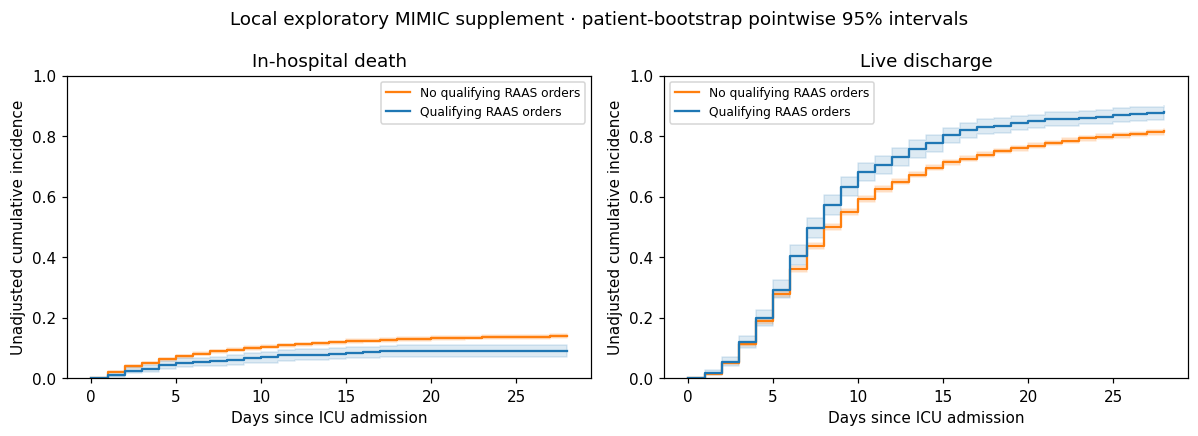

In [5]:
ANALYSIS = "competing"
figure = style_competing_figure(plot_supplement(bundle, ANALYSIS), result)
display(figure)
plt.close(figure)

**How to read**

- Blue represents qualifying RAAS orders and orange represents no qualifying orders. The left curve is death CIF and the right is live-discharge CIF; shading shows pointwise patient-bootstrap 95% intervals. Read each curve as an unadjusted cumulative probability by time, not as a hazard ratio.
- This runtime plot uses a 0–100% vertical range for both panels, while the saved public death panel uses 0–20%. The scale difference changes appearance, not the definition of the probability. The default synthetic bootstrap uses fewer draws than the saved clinical run.

**What the results show**

The curves and table describe cumulative incidence for the selected execution input. Read its day-specific values from the table above.

**Interpretation limits**

- Check the title and printed `data_origin`: SYNTHETIC values demonstrate software behavior only. The clinical results are the separately labeled saved aggregate figure above.
- Treat death and discharge as competing endpoints. The separate adjusted cause-specific Cox table estimates rates among admissions still alive and hospitalized. Curve separation or HR differences do not establish a causal treatment effect.

## Takeaways

Read death and discharge curves together. A cause-specific HR describes the instantaneous rate while still alive and hospitalized; the CIF describes the observed probability of a hospital endpoint by a specified time. The unadjusted CIF difference does not establish a treatment effect. Published Kaplan-Meier curves must not be read as competing-risk-adjusted absolute death probabilities.

See [the supplement guide](../docs/SURVIVAL_SENSITIVITY_SUPPLEMENTS.md) for the execution commands, data handling, reference checks and limitations. Tracked notebooks retain only the reviewed aggregate outputs bound in [the execution record](../docs/NOTEBOOK_EXECUTION_VALIDATION.json); full local result bundles stay under ignored `reports/local_supplements/`.